In [22]:
import os
import sys
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

import json, logging, re, shutil
from pathlib import Path

project_root = next(
    (
        candidate
        for candidate in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
        if (candidate / "utils" / "__init__.py").is_file()
        and (candidate / "model" / "MSR.py").is_file()
    ),
    None,
)
if project_root is None:
    raise RuntimeError(f"Could not find the project root above {Path.cwd()}")
os.chdir(project_root)
sys.path.insert(0, str(project_root))


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import kagglehub
from PIL import Image
import hashlib

import torch
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from torchvision.transforms import InterpolationMode
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import label_binarize
from sklearn.metrics import (confusion_matrix, roc_auc_score)

from utils.config import *
from utils.log import *
from data.dataset_loader import *
from model.MSR import MSR

## Data: original-data CSV, patient ID, seed-42 split

In [23]:
DATA_PATH = kagglehub.dataset_download(DATASETS[DATASET]["kaggle"])
log.info(f"Dataset '{DATASET}' downloaded to {DATA_PATH}")

2026-11-10 00:18:23 | Dataset 'kermany' downloaded to C:\Users\dehoa\.cache\kagglehub\datasets\paultimothymooney\chest-xray-pneumonia\versions\2


In [24]:
IMG_EXT = {".png", ".jpg", ".jpeg"}


def _images(folder):
    return sorted(f for f in os.listdir(folder)
                  if Path(f).suffix.lower() in IMG_EXT and os.path.isfile(os.path.join(folder, f)))

def extract_patient_id(dataset, filename):
    """Best-effort patient ID from a file name; None when the dataset does not encode it."""
    stem = Path(filename).stem
    if dataset == "kermany":
        m = re.match(r"(person\d+)_(?:bacteria|virus)_\d+", stem, re.I)       # pneumonia
        if m:
            return m.group(1).lower()
        m = re.match(r"((?:NORMAL2-)?IM-\d{4})-\d{4}", stem, re.I)             # normal
        if m:
            return m.group(1).upper()
    return None


def _row(dataset, root, class_name, folder, fname, orig_split=None):
    path = os.path.join(folder, fname)
    return dict(dataset=dataset, class_name=class_name, filename=fname, image_path=path,
                rel_path=os.path.relpath(path, root), patient_id=extract_patient_id(dataset, fname),
                orig_split=orig_split)


def scan_rahman(root):
    rows = []
    for cls in sorted(os.listdir(root)):
        img_dir, mask_dir = os.path.join(root, cls, "images"), os.path.join(root, cls, "masks")
        if not os.path.isdir(img_dir):
            continue
        masks = set(os.listdir(mask_dir)) if os.path.isdir(mask_dir) else set()
        for f in _images(img_dir):
            r = _row("rahman", root, cls, img_dir, f)
            r["mask_path"] = os.path.join(mask_dir, f) if f in masks else None   # masks share the image file name
            rows.append(r)
    return rows


def scan_kermany(root):
    wanted = {"train", "val", "test"}
    split_dirs = lambda p: [d for d in os.listdir(p) if os.path.isdir(os.path.join(p, d)) and d.lower() in wanted]
    found = split_dirs(root)
    if not found:                                    # data may be nested one level deeper
        for sub in sorted(os.listdir(root)):
            sub_path = os.path.join(root, sub)
            if os.path.isdir(sub_path) and split_dirs(sub_path):
                root, found = sub_path, split_dirs(sub_path)
                break
    rows = []
    for split in sorted(found):
        split_dir = os.path.join(root, split)
        for cls in sorted(os.listdir(split_dir)):
            cls_dir = os.path.join(split_dir, cls)
            if os.path.isdir(cls_dir):
                rows += [_row("kermany", root, cls, cls_dir, f, split.lower()) for f in _images(cls_dir)]
    return rows


def scan_cohen(root):
    rows = []
    for split in ("train", "test"):                  # same order as the original notebook
        split_dir = os.path.join(root, split)
        if not os.path.isdir(split_dir):
            continue
        for cls in sorted(os.listdir(split_dir)):
            cls_dir = os.path.join(split_dir, cls)
            if os.path.isdir(cls_dir):
                rows += [_row("cohen", root, cls, cls_dir, f, split) for f in _images(cls_dir)]
    return rows


def make_splits(df, seed):
    """Stratified 80 / 10 / 10 split (identical procedure for every dataset)."""
    tr, tmp = train_test_split(df, test_size=0.2, random_state=seed, stratify=df["label"])
    va, ts = train_test_split(tmp, test_size=0.5, random_state=seed, stratify=tmp["label"])
    return tr.reset_index(drop=True), va.reset_index(drop=True), ts.reset_index(drop=True)


def split_summary(splits: dict, class_names):
    """Class counts per split + patient overlap between splits (when patient IDs exist)."""
    rows = []
    for name, d in splits.items():
        row = {"split": name, "n_images": len(d)}
        row.update({c: int((d["class_name"] == c).sum()) for c in class_names})
        row["n_patients"] = d["patient_id"].nunique() if d["patient_id"].notna().any() else None
        rows.append(row)
    summary = pd.DataFrame(rows)
    leak = {}
    if splits["train"]["patient_id"].notna().any():
        for a, b in (("train", "val"), ("train", "test"), ("val", "test")):
            shared = set(splits[a]["patient_id"].dropna()) & set(splits[b]["patient_id"].dropna())
            leak[f"{a}&{b}"] = dict(shared_patients=len(shared),
                                    images_in_second_split=int(splits[b]["patient_id"].isin(shared).sum()))
    return summary, leak


def load_split_csvs(csv_dir, dataset, seed, root):
    """Reload the train/val/test CSVs of an earlier run. If the saved image paths do not exist on this machine
    (e.g. different Kaggle mount), they are rebuilt from the saved relative paths and the current dataset root."""
    splits = {}
    for name in ("train", "val", "test"):
        f = Path(csv_dir) / f"{dataset}_seed{seed}_{name}.csv"
        if not f.exists():
            raise FileNotFoundError(f"Split CSV not found: {f}")
        d = pd.read_csv(f)
        moved = ~d["image_path"].map(os.path.exists)
        if moved.any():
            d.loc[moved, "image_path"] = d.loc[moved, "rel_path"].map(lambda r: os.path.join(root, r))
            if "mask_path" in d:
                has_mask = moved & d["mask_path"].notna()
                d.loc[has_mask, "mask_path"] = d.loc[has_mask, "rel_path"].map(
                    lambda r: os.path.join(root, r.replace(os.sep + "images" + os.sep, os.sep + "masks" + os.sep)))
        missing = ~d["image_path"].map(os.path.exists)
        if missing.any():
            raise FileNotFoundError(f"{missing.sum()} images of '{name}' split not found, e.g. {d.loc[missing, 'image_path'].iloc[0]}")
        splits[name] = d
    return splits

In [25]:
root = os.path.join(DATA_PATH, DATASETS[DATASET]["root"])

if SPLIT_CSV_DIR is None:
    rows = {"rahman": scan_rahman, "kermany": scan_kermany, "cohen": scan_cohen}[DATASET](root)
    original_df = pd.DataFrame(rows)
    class_names = sorted(original_df["class_name"].unique())
    label_map = {name: i for i, name in enumerate(class_names)}
    original_df["label"] = original_df["class_name"].map(label_map)
    original_df.insert(0, "row_id", range(len(original_df)))
    original_df.to_csv(DATA_DIR / f"{DATASET}_original.csv", index=False)
    tr_df, val_df, ts_df = make_splits(original_df, SPLIT_SEED)
    for name, d in {"train": tr_df, "val": val_df, "test": ts_df}.items():
        d.to_csv(DATA_DIR / f"{DATASET}_seed{SPLIT_SEED}_{name}.csv", index=False)
    log.info(f"Original data: {len(original_df)} images | stratified 80/10/10 split, seed {SPLIT_SEED}")
else:                                           # ---- reuse a saved split ----
    loaded = load_split_csvs(SPLIT_CSV_DIR, DATASET, SPLIT_SEED, root)
    tr_df, val_df, ts_df = loaded["train"], loaded["val"], loaded["test"]
    original_df = pd.concat(loaded.values()).sort_values("row_id").reset_index(drop=True)
    class_names = sorted(original_df["class_name"].unique())
    label_map = {name: i for i, name in enumerate(class_names)}
    assert (original_df["class_name"].map(label_map) == original_df["label"]).all(), "label ids in CSV do not match class names"
    assert not set(tr_df["row_id"]) & set(ts_df["row_id"]) and not set(val_df["row_id"]) & set(ts_df["row_id"]) \
        and not set(tr_df["row_id"]) & set(val_df["row_id"]), "splits overlap"
    log.info(f"Loaded split CSVs from {SPLIT_CSV_DIR} (no re-splitting, no new split CSVs written)")

num_classes = len(class_names)
splits = {"train": tr_df, "val": val_df, "test": ts_df}
(OUT_DIR / "class_mapping.json").write_text(json.dumps(label_map, indent=2))
log.info(f"{len(original_df)} images | label map {label_map}")
log.info("Patient IDs: " + (f"{original_df['patient_id'].nunique()} unique patients extracted from file names"
                            if original_df["patient_id"].notna().any() else "not available for this dataset"))

summary, leak = split_summary(splits, class_names)
summary.to_csv(DATA_DIR / f"{DATASET}_seed{SPLIT_SEED}_split_summary.csv", index=False)
log.info(f"Split sizes:\n{summary.to_string(index=False)}")
for pair, v in leak.items():
    log.info(f"Patient overlap {pair}: {v}")

2026-11-10 00:18:23 | Loaded split CSVs from ./csv/kermany (no re-splitting, no new split CSVs written)
2026-11-10 00:18:23 | 5856 images | label map {'NORMAL': 0, 'PNEUMONIA': 1}
2026-11-10 00:18:23 | Patient IDs: 3118 unique patients extracted from file names
2026-11-10 00:18:23 | Split sizes:
split  n_images  NORMAL  PNEUMONIA  n_patients
train      4684    1266       3418        2713
  val       586     159        427         514
 test       586     158        428         523
2026-11-10 00:18:23 | Patient overlap train&val: {'shared_patients': 308, 'images_in_second_split': 371}
2026-11-10 00:18:23 | Patient overlap train&test: {'shared_patients': 308, 'images_in_second_split': 363}
2026-11-10 00:18:23 | Patient overlap val&test: {'shared_patients': 84, 'images_in_second_split': 107}


## Cross-dataset experiments

In [26]:
MODELS_TO_RUN = ["rahman-full", "rahman-eca", "rahman-full-aug", "rahman-eca-aug"]
DATASETS_TO_RUN = ["kermany_test", "cohen_test", "cohen3_test"]   # cohen3_test = Cohen with all 3 classes
TEST_ONLY = True
EXT_DIR = Path("/kaggle/working/external_tests")
EXT_DIR.mkdir(parents=True, exist_ok=True)   # every model writes into its own sub-folder EXT_DIR/<model>/

SPLIT_DIRS = {
    "kermany": "./csv/kermany",
    "cohen":   "./csv/cohen",
    "rahman": "./csv/rahman"
}

THRESHOLD = 0.5
N_BOOT = 1000
NUM_WORKERS = 2
_RAHMAN_GROUPS = {
    "pneumonia_only": {"NORMAL": [2], "PNEUMONIA": [3]},
    "any_pathology":  {"NORMAL": [2], "PNEUMONIA": [0, 1, 3]},
}
# 3-class Cohen (COVID19 / NORMAL / PNEUMONIA) from the 4-way Rahman output [0 COVID, 1 Lung_Opacity, 2 Normal, 3 Viral Pneumonia]
_RAHMAN_GROUPS3 = {
    "strict":               {"COVID19": [0], "NORMAL": [2], "PNEUMONIA": [3]},
    "opacity_as_pneumonia": {"COVID19": [0], "NORMAL": [2], "PNEUMONIA": [1, 3]},
}
_P = "./model/weights"

MODELS = {
    "rahman-eca":      dict(weights=f"{_P}/eca_LN_rahman42.pth",
                            num_classes=4, train_dataset="rahman", encoder_output=False, groups=_RAHMAN_GROUPS, groups3=_RAHMAN_GROUPS3),
    "rahman-eca-aug":  dict(weights=f"{_P}/eca_LN_rahman42_aug.pth",
                            num_classes=4, train_dataset="rahman", encoder_output=False, groups=_RAHMAN_GROUPS, groups3=_RAHMAN_GROUPS3),
    "rahman-full":     dict(weights=f"{_P}/dsa_eca_LN_rahman42.pth",
                            num_classes=4, train_dataset="rahman", encoder_output=False, groups=_RAHMAN_GROUPS, groups3=_RAHMAN_GROUPS3),
    "rahman-full-aug": dict(weights=f"{_P}/dsa_eca_LN_rahman42_aug.pth",
                            num_classes=4, train_dataset="rahman", encoder_output=False, groups=_RAHMAN_GROUPS, groups3=_RAHMAN_GROUPS3),
}

CHECK_COHEN_OVERLAP = True

EVAL_NAMES = ["NORMAL", "PNEUMONIA"]
EVAL3_NAMES = ["COVID19", "NORMAL", "PNEUMONIA"]   # label ids 0 / 1 / 2 for the 3-class Cohen test
THREE_CLASS = {"cohen3_test"}                       # datasets evaluated as 3-class (argmax, no threshold)

DEAD_PREFIXES = ("cross_scale_attention.",)

preprocess = transforms.Compose([      # same as transform_val
    transforms.Resize(IMAGE_SIZE, interpolation=InterpolationMode.BICUBIC),
    transforms.ToTensor(),
])


In [27]:
def _binary_frame(d, neg, pos, tag):
    """Keep only the `neg` / `pos` classes (case-insensitive, '_' treated as space) and return the standard frame."""
    cls = d["class_name"].str.upper().str.replace("_", " ")
    log.info(f"{tag}: classes in split {cls.value_counts().to_dict()} -> keeping {neg} vs {pos}")
    keep = cls.isin([neg, pos])
    d, cls = d[keep].reset_index(drop=True), cls[keep].reset_index(drop=True)
    return pd.DataFrame({
        "name": d["filename"], "image_path": d["image_path"],
        "label": (cls == pos).astype(int),
        "group": _group_ids(d["patient_id"], len(d)),     # missing patient IDs: each image is its own group
    })

def _group_ids(ids, n):
    ids = pd.Series(list(ids)).astype(object)
    return np.where(ids.isna(), "img_" + pd.Series(range(n)).astype(str), ids.astype(str)).astype(str)

def load_split_csv(ds):
    root = os.path.join(kagglehub.dataset_download(DATASETS[ds]["kaggle"]), DATASETS[ds]["root"])
    splits = load_split_csvs(SPLIT_DIRS[ds], ds, SPLIT_SEED, root)
    return splits["test"] if TEST_ONLY else pd.concat(splits.values(), ignore_index=True)

def build_kermany():
    assert DATASET == "kermany", "build_kermany reads ts_df/original_df, which are loaded for DATASET"
    src = ts_df if TEST_ONLY else original_df
    return _binary_frame(src.reset_index(drop=True), "NORMAL", "PNEUMONIA", "Kermany")

def build_cohen():
    out = _binary_frame(load_split_csv("cohen"), "NORMAL", "PNEUMONIA", "Cohen")
    if CHECK_COHEN_OVERLAP:
        check_overlap(out, original_df, "Cohen vs Kermany")
    return out

def build_cohen3():
    """Cohen test split with all 3 classes: COVID19 = 0, NORMAL = 1, PNEUMONIA = 2."""
    d = load_split_csv("cohen")
    cls = d["class_name"].str.upper().str.replace("_", " ")
    log.info(f"Cohen 3-class: classes in split {cls.value_counts().to_dict()} -> keeping {EVAL3_NAMES}")
    keep = cls.isin(EVAL3_NAMES)
    d, cls = d[keep].reset_index(drop=True), cls[keep].reset_index(drop=True)
    out = pd.DataFrame({
        "name": d["filename"], "image_path": d["image_path"],
        "label": cls.map({c: i for i, c in enumerate(EVAL3_NAMES)}).astype(int),
        "group": _group_ids(d["patient_id"], len(d)),
    })
    if CHECK_COHEN_OVERLAP:
        check_overlap(out, original_df, "Cohen 3-class vs Kermany")
    return out

def index_images(root):
    idx = {}
    for dp, _, files in os.walk(root):
        for f in files:
            if f.lower().endswith(".png"):
                idx[f] = os.path.join(dp, f)
    return idx

def _md5(p):
    with open(p, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()

def check_overlap(df_ext, df_ref, tag):
    """Catches byte-identical files and shared file names only; re-encoded or resized copies are not detected."""
    ref_hash = {_md5(p) for p in df_ref["image_path"]}
    dup = sum(_md5(p) in ref_hash for p in df_ext["image_path"])
    same_name = int(df_ext["name"].isin(set(df_ref["filename"])).sum())
    log.info(f"{tag}: {dup}/{len(df_ext)} byte-identical images, {same_name}/{len(df_ext)} shared file names")

class ExternalDataset(Dataset):
    def __init__(self, df):
        self.paths, self.labels = df["image_path"].tolist(), df["label"].tolist()

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        return preprocess(Image.open(self.paths[i]).convert("RGB")), self.labels[i]

In [28]:
# ============== Clean report: standard classification metrics, one table per model ==============
def clean_report(results, root=None, save=True):
    """results: dict returned by main(). Binary and 3-class confusion matrices are saved by main() under <model>/confusion_matrices."""
    root = Path(root or EXT_DIR)
    pd.set_option("display.width", 200)
    for mname, res in results.items():
        print(f"\n{'=' * 24} {mname} {'=' * 24}")
        out = {}
        b, t = res["binary"], res["three_class"]

        if len(b):                                    # ---- binary (NORMAL vs PNEUMONIA, threshold = THRESHOLD)
            d = b.copy()
            d["precision"] = d.tp / (d.tp + d.fp).clip(lower=1)
            d["recall"] = d.sensitivity
            d["f1"] = 2 * d.precision * d.recall / (d.precision + d.recall).clip(lower=1e-12)
            tab = d[["dataset", "variant", "n", "n_pos", "accuracy", "precision", "recall", "specificity",
                     "f1", "auc_micro", "balanced_accuracy", "auroc"]].round(4)
            print("\nBinary (NORMAL vs PNEUMONIA, positive = PNEUMONIA)"); print(tab.to_string(index=False))
            out["binary"] = tab

        if len(t):                                    # ---- 3-class overall
            tab = t[["dataset", "variant", "n", "accuracy", "macro_precision", "balanced_accuracy", "macro_f1",
                     "auc_micro", "auroc_macro_ovr"]].rename(columns={"balanced_accuracy": "macro_recall"}).round(4)
            print("\n3-class overall (macro = unweighted mean over classes; macro_recall == balanced accuracy)")
            print(tab.to_string(index=False))
            out["three_class"] = tab

            rows = []                                 # ---- 3-class per class (precision/F1 from the saved confusion matrix)
            for _, r in t.iterrows():
                cm = pd.read_csv(root / mname / "confusion_matrices" / f"confusion_matrix__{r['dataset']}__{r['variant']}.csv", index_col=0).to_numpy()
                for i, c in enumerate(EVAL3_NAMES):
                    tp_, pred, sup = cm[i, i], cm[:, i].sum(), cm[i].sum()
                    prec, rec = tp_ / max(pred, 1), tp_ / max(sup, 1)
                    rows.append(dict(dataset=r["dataset"], variant=r["variant"], cls=c, support=int(sup),
                                     precision=prec, recall=rec, specificity=r[f"spec_{c}"],
                                     f1=2 * prec * rec / max(prec + rec, 1e-12), auroc=r[f"auroc_{c}"]))
            pc = pd.DataFrame(rows).round(4)
            print("\n3-class per class (one-vs-rest)"); print(pc.to_string(index=False))
            out["per_class"] = pc

        if save:
            for k, v in out.items():
                v.to_csv(root / mname / f"generic_metrics_{ {'binary': 'binary', 'three_class': '3class_overall', 'per_class': '3class_per_class'}[k] }.csv", index=False)

In [ ]:
# ============================== MODEL / INFERENCE ==============================
from utils.load_model import load_model


@torch.no_grad()
def predict(model, df):
    # Notebook evaluation runs in-process to avoid Windows/Jupyter worker crashes.
    loader = DataLoader(ExternalDataset(df), batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
    return np.concatenate([torch.softmax(model(x.to(device)), dim=1).cpu().numpy() for x, _ in loader])


def project(raw, groups, names=EVAL_NAMES):
    p = np.stack([raw[:, groups[c]].sum(axis=1) for c in names], axis=1)
    return p / np.clip(p.sum(axis=1, keepdims=True), 1e-12, None)      # rows sum to 1 over the two eval classes


# ============================== METRICS ==============================
def point_metrics(y, p, thr):
    yhat = p >= thr
    tp = int((yhat & (y == 1)).sum()); fn = int((~yhat & (y == 1)).sum())
    tn = int((~yhat & (y == 0)).sum()); fp = int((yhat & (y == 0)).sum())
    sens, spec = tp / max(tp + fn, 1), tn / max(tn + fp, 1)
    return dict(n=int(len(y)), n_pos=int((y == 1).sum()),
            auroc=float(roc_auc_score(y, p)),
            auc_micro=float(roc_auc_score(y, p)),
            sensitivity=sens, specificity=spec, balanced_accuracy=(sens + spec) / 2,
            accuracy=(tp + tn) / len(y), tn=tn, fp=fp, fn=fn, tp=tp)


def bootstrap_ci(y, p, groups, thr, n_boot=N_BOOT):
    """95% percentile CI; resamples whole patients when a group has several images."""
    rng = np.random.default_rng(SEED)
    _, inv = np.unique(groups, return_inverse=True)
    n_groups = inv.max() + 1
    members = None
    if n_groups < len(y):
        order = np.argsort(inv, kind="stable")
        bounds = np.searchsorted(inv[order], np.arange(n_groups + 1))
        members = [order[bounds[i]:bounds[i + 1]] for i in range(n_groups)]
    keys = ["auroc", "sensitivity", "specificity", "balanced_accuracy"]
    draws = {k: [] for k in keys}
    for _ in range(n_boot):
        if members is None:
            idx = rng.integers(0, len(y), len(y))
        else:
            idx = np.concatenate([members[i] for i in rng.integers(0, n_groups, n_groups)])
        if y[idx].min() == y[idx].max():
            continue
        m = point_metrics(y[idx], p[idx], thr)
        for k in keys:
            draws[k].append(m[k])
    return {k: np.percentile(v, [2.5, 97.5]).tolist() for k, v in draws.items()}


# ---------- 3-class metrics (argmax decision) ----------
def multiclass_metrics(y, P, per_class=True):
    k = P.shape[1]
    cm = confusion_matrix(y, P.argmax(1), labels=list(range(k)))
    diag = np.diag(cm).astype(float)
    sens = diag / np.clip(cm.sum(1), 1, None)                       # per-class recall
    prec = diag / np.clip(cm.sum(0), 1, None)
    fp = cm.sum(0) - diag
    tn = cm.sum() - cm.sum(0) - cm.sum(1) + diag
    spec = tn / np.clip(tn + fp, 1, None)
    f1 = 2 * prec * sens / np.clip(prec + sens, 1e-12, None)
    m = dict(n=int(len(y)), accuracy=float(diag.sum() / cm.sum()), balanced_accuracy=float(sens.mean()),
            macro_precision=float(prec.mean()), macro_f1=float(f1.mean()),
            auc_micro=float(roc_auc_score(label_binarize(y, classes=list(range(k))), P, average="micro")),
            auroc_macro_ovr=float(roc_auc_score(y, P, multi_class="ovr", average="macro", labels=list(range(k)))))
    if per_class:
        for i, c in enumerate(EVAL3_NAMES):
            m.update({f"n_{c}": int((y == i).sum()), f"sens_{c}": float(sens[i]), f"spec_{c}": float(spec[i]),
                      f"auroc_{c}": float(roc_auc_score(y == i, P[:, i]))})
    return m, cm


def bootstrap_ci_multi(y, P, groups, n_boot=N_BOOT):
    """95% percentile CI for the 3-class metrics; resamples whole patients when a group has several images."""
    rng = np.random.default_rng(SEED)
    _, inv = np.unique(groups, return_inverse=True)
    n_groups = inv.max() + 1
    members = None
    if n_groups < len(y):
        order = np.argsort(inv, kind="stable")
        bounds = np.searchsorted(inv[order], np.arange(n_groups + 1))
        members = [order[bounds[i]:bounds[i + 1]] for i in range(n_groups)]
    keys = ["accuracy", "balanced_accuracy", "macro_f1", "auc_micro", "auroc_macro_ovr"]
    draws = {k: [] for k in keys}
    for _ in range(n_boot):
        if members is None:
            idx = rng.integers(0, len(y), len(y))
        else:
            idx = np.concatenate([members[i] for i in rng.integers(0, n_groups, n_groups)])
        if len(np.unique(y[idx])) < P.shape[1]:                      # AUROC needs every class present
            continue
        m, _ = multiclass_metrics(y[idx], P[idx], per_class=False)
        for k in keys:
            draws[k].append(m[k])
    return {k: np.percentile(v, [2.5, 97.5]).tolist() for k, v in draws.items()}


# ============================== PER-MODEL OUTPUT ==============================
def model_dir(mname):
    d = EXT_DIR / mname
    (d / "raw_predictions").mkdir(parents=True, exist_ok=True)
    (d / "confusion_matrices").mkdir(parents=True, exist_ok=True)
    return d

def attach_model_log(mdir):
    """Per-model log file <mdir>/evaluation.log; returns the handler so it can be removed afterwards."""
    h = logging.FileHandler(Path(mdir) / "evaluation.log", mode="a")
    h.setFormatter(logging.Formatter("%(asctime)s | %(message)s", "%Y-%m-%d %H:%M:%S"))
    log.addHandler(h)
    return h


# ============================== RUN ==============================
BUILDERS = {"kermany_test": ("kermany", build_kermany), "cohen_test": ("cohen", build_cohen),
            "cohen3_test": ("cohen", build_cohen3)} #,"rahman_test": ("rahman", build_rahman)}

def main():
    data = {}
    for key in DATASETS_TO_RUN:
        data[key] = BUILDERS[key][1]()
        names = EVAL3_NAMES if key in THREE_CLASS else EVAL_NAMES
        log.info(f"{key}: {len(data[key])} images | {data[key]['label'].map(dict(enumerate(names))).value_counts().to_dict()}")

    all_results = {}
    for mname in MODELS_TO_RUN:
        spec = MODELS[mname]
        if not os.path.exists(spec["weights"]):
            log.warning(f"[{mname}] weights not found at {spec['weights']}, skipped")
            continue
        mdir = model_dir(mname)
        handler = attach_model_log(mdir)                      
        rows_bin, rows_3 = [], []
        try:
            (mdir / "evaluation_config.json").write_text(json.dumps(
                dict(model=mname, **spec, threshold=THRESHOLD, n_boot=N_BOOT, seed=SEED,
                     datasets=DATASETS_TO_RUN, test_only=TEST_ONLY), indent=2))
            model,_ = load_model(spec["weights"], spec["num_classes"])
            log.info(f"[{mname}] loaded (encoder_output={spec['encoder_output']})")
            for dkey in DATASETS_TO_RUN:
                df = data[dkey]
                raw = predict(model, df)
                pd.DataFrame(raw, columns=[f"raw_{i}" for i in range(raw.shape[1])]).assign(
                    name=df["name"].values, label=df["label"].values
                    ).to_csv(mdir / "raw_predictions" / f"{dkey}__softmax_probabilities.csv", index=False)

                y, groups = df["label"].to_numpy(), df["group"].to_numpy()
                in_domain = spec["train_dataset"] == BUILDERS[dkey][0]
                if dkey in THREE_CLASS:
                    for variant, grp in spec["groups3"].items():
                        P = project(raw, grp, EVAL3_NAMES)
                        res, cm = multiclass_metrics(y, P)
                        ci = bootstrap_ci_multi(y, P, groups)
                        rows_3.append(dict(model=mname, variant=variant, dataset=dkey, in_domain=in_domain, **res,
                                **{f"{k}_lo": v[0] for k, v in ci.items()},
                                **{f"{k}_hi": v[1] for k, v in ci.items()}))
                        pd.DataFrame(cm, index=[f"true_{c}" for c in EVAL3_NAMES],
                                columns=[f"pred_{c}" for c in EVAL3_NAMES]).to_csv(
                                mdir / "confusion_matrices" / f"confusion_matrix__{dkey}__{variant}.csv")
                        log.info(f"[{mname}/{variant}] {dkey} (3-class): acc {res['accuracy']:.4f} | "
                                f"macro-F1 {res['macro_f1']:.3f} | micro-AUROC {res['auc_micro']:.4f} | "
                                f"bal.acc {res['balanced_accuracy']:.3f}")
                else:
                    for variant, grp in spec["groups"].items():
                        p = project(raw, grp)[:, 1]
                        res = point_metrics(y, p, THRESHOLD)

                        # Save binary confusion matrix (rows = true labels, columns = predictions).
                        # Label order follows EVAL_NAMES: NORMAL=0, PNEUMONIA=1.
                        cm_bin = np.array([
                            [res["tn"], res["fp"]],
                            [res["fn"], res["tp"]],
                        ], dtype=int)
                        pd.DataFrame(
                            cm_bin,
                            index=[f"true_{c}" for c in EVAL_NAMES],
                            columns=[f"pred_{c}" for c in EVAL_NAMES],
                        ).to_csv(
                            mdir / "confusion_matrices" /
                            f"confusion_matrix__{dkey}__{variant}.csv"
                        )

                        ci = bootstrap_ci(y, p, groups, THRESHOLD)
                        rows_bin.append(dict(model=mname, variant=variant, dataset=dkey, in_domain=in_domain,
                                             threshold=THRESHOLD, **res,
                                             **{f"{k}_lo": v[0] for k, v in ci.items()},
                                             **{f"{k}_hi": v[1] for k, v in ci.items()}))
                        log.info(f"[{mname}/{variant}] {dkey}: AUROC {res['auroc']:.4f} | sens {res['sensitivity']:.3f} | "
                                 f"spec {res['specificity']:.3f} | bal.acc {res['balanced_accuracy']:.3f}")
            del model
        finally:
            log.removeHandler(handler); handler.close()

        # results are written per model (no combined file across models)
        res_bin, res_3 = pd.DataFrame(rows_bin), pd.DataFrame(rows_3)
        if len(res_bin):
            res_bin.to_csv(mdir / "full_results_with_ci_binary.csv", index=False)
        if len(res_3):
            res_3.to_csv(mdir / "full_results_with_ci_3class.csv", index=False)
        shutil.make_archive(str(EXT_DIR / mname), "zip", root_dir=mdir)      # one zip per model
        all_results[mname] = dict(binary=res_bin, three_class=res_3)

        print(f"\n===== {mname} =====")
        if len(res_bin):
            show = res_bin[["model", "variant", "dataset", "in_domain", "n", "n_pos"]].copy()
            for k in ["auroc", "sensitivity", "specificity", "balanced_accuracy"]:
                show[k] = res_bin.apply(lambda r: f"{r[k]:.3f} [{r[k + '_lo']:.3f}, {r[k + '_hi']:.3f}]", axis=1)
            show["accuracy"] = res_bin["accuracy"].round(4)
            print(show.to_string(index=False))
        if len(res_3):
            show = res_3[["model", "variant", "dataset", "in_domain", "n"]].copy()
            for k in ["accuracy", "balanced_accuracy", "macro_f1", "auc_micro", "auroc_macro_ovr"]:
                show[k] = res_3.apply(lambda r: f"{r[k]:.3f} [{r[k + '_lo']:.3f}, {r[k + '_hi']:.3f}]", axis=1)
            print(show.to_string(index=False))
    return all_results


results = main()

clean_report(results)

In [ ]:
# ============== Experiment: Kermany / Cohen test sets WITHOUT images that match Rahman's training set ==============
from concurrent.futures import ThreadPoolExecutor

NR_DIR = Path("csv/external_tests_no_rahman_overlap")
RAHMAN_SPLIT_CSV_DIR = None        # folder with rahman_seed42_{train,val,test}.csv -> match against the TRAIN split only
                                   # None -> match against the WHOLE Rahman dataset (strictest; a superset of the train split)
RAHMAN_REF_SPLITS = ("train",)     # only used when RAHMAN_SPLIT_CSV_DIR is set
THUMB = 64

NCC_THRESHOLD = 0.98


def _thumb(path):
    im = Image.open(path).convert("L").resize((THUMB, THUMB), Image.BOX)
    return np.asarray(im, dtype=np.float32).ravel()

def thumbnails(paths):
    with ThreadPoolExecutor(8) as ex:
        return np.stack(list(ex.map(_thumb, paths)))

def _unit(x):
    x = x - x.mean(1, keepdims=True)
    return (x / np.clip(np.linalg.norm(x, axis=1, keepdims=True), 1e-6, None)).astype(np.float32)

_RAHMAN_REF = {}
def rahman_reference():
    """Rahman reference images (+ their unit thumbnails), computed once."""
    if not _RAHMAN_REF:
        root = os.path.join(kagglehub.dataset_download(DATASETS["rahman"]["kaggle"]), DATASETS["rahman"]["root"])
        if RAHMAN_SPLIT_CSV_DIR is None:
            ref, what = pd.DataFrame(scan_rahman(root)), "whole Rahman dataset"
        else:
            sp = load_split_csvs(RAHMAN_SPLIT_CSV_DIR, "rahman", SPLIT_SEED, root)
            ref, what = pd.concat([sp[s] for s in RAHMAN_REF_SPLITS], ignore_index=True), f"Rahman {'+'.join(RAHMAN_REF_SPLITS)}"
        ref = ref.reset_index(drop=True)
        log.info(f"Rahman reference: {len(ref)} images ({what}); computing {THUMB}x{THUMB} thumbnails ...")
        _RAHMAN_REF.update(df=ref, x=_unit(thumbnails(ref["image_path"].tolist())), what=what)
    return _RAHMAN_REF["df"], _RAHMAN_REF["x"], _RAHMAN_REF["what"]

def nearest_match(test_x, ref_x, chunk=256):
    """For every test thumbnail: best correlation with any Rahman image, and that image's index."""
    A = _unit(test_x)
    sims, idx = [], []
    if device.type == "cuda":
        with torch.no_grad():
            B = torch.from_numpy(ref_x).to(device)
            for i in range(0, len(A), chunk):
                v, j = (torch.from_numpy(A[i:i + chunk]).to(device) @ B.T).max(1)
                sims.append(v.cpu().numpy()); idx.append(j.cpu().numpy())
    else:
        for i in range(0, len(A), chunk):
            s = A[i:i + chunk] @ ref_x.T
            idx.append(s.argmax(1)); sims.append(s.max(1))
    return np.concatenate(sims), np.concatenate(idx)

def save_match_montage(rep, path, n=6):
    """Decision-boundary check: the n weakest matches that were REMOVED and the n strongest that were KEPT."""
    sel = pd.concat([rep[rep["matched"]].nsmallest(n, "best_sim"), rep[~rep["matched"]].nlargest(n, "best_sim")])
    if sel.empty:
        return
    fig, ax = plt.subplots(len(sel), 2, figsize=(5, 2.3 * len(sel)), squeeze=False)
    for a_row, (_, r) in zip(ax, sel.iterrows()):
        a_row[0].imshow(Image.open(r["image_path"]).convert("L"), cmap="gray")
        a_row[1].imshow(Image.open(r["rahman_path"]).convert("L"), cmap="gray")
        a_row[0].set_title(f"{'REMOVED' if r['matched'] else 'kept'}  r={r['best_sim']:.3f}", fontsize=8)
        a_row[1].set_title(f"Rahman: {r['rahman_class']}", fontsize=8)
        for a in a_row:
            a.axis("off")
    fig.tight_layout(); fig.savefig(path, dpi=120); plt.show(); plt.close(fig)

def drop_rahman_matches(df, tag):
    """Remove every test image whose best Rahman match has correlation >= NCC_THRESHOLD; write the match table + montage."""
    ref, ref_x, what = rahman_reference()
    sim, j = nearest_match(thumbnails(df["image_path"].tolist()), ref_x)
    hit = sim >= NCC_THRESHOLD
    rep = pd.DataFrame({"name": df["name"].values, "label": df["label"].values, "image_path": df["image_path"].values,
                        "best_sim": sim, "matched": hit, "rahman_file": ref["filename"].values[j],
                        "rahman_class": ref["class_name"].values[j], "rahman_path": ref["image_path"].values[j]})
    NR_DIR.mkdir(parents=True, exist_ok=True)
    rep.to_csv(NR_DIR / f"overlap_{tag}.csv", index=False)
    save_match_montage(rep, NR_DIR / f"overlap_{tag}_examples.png")
    kept = df[~hit].reset_index(drop=True)
    cnt = lambda d: d["label"].value_counts().sort_index().to_dict()
    log.info(f"{tag}: removed {int(hit.sum())}/{len(df)} images matching {what} (NCC >= {NCC_THRESHOLD}) | "
             f"label counts {cnt(df)} -> {cnt(kept)}")
    if kept["label"].nunique() < df["label"].nunique():
        raise RuntimeError(f"{tag}: a whole class was removed by the overlap filter; check NCC_THRESHOLD")
    return kept

2026-11-10 00:12:58 | Kermany: classes in split {'PNEUMONIA': 428, 'NORMAL': 158} -> keeping NORMAL vs PNEUMONIA
2026-11-10 00:12:59 | kermany_test: 586 images | {'PNEUMONIA': 428, 'NORMAL': 158}
2026-11-10 00:12:59 | Kermany: classes in split {'PNEUMONIA': 428, 'NORMAL': 158} -> keeping NORMAL vs PNEUMONIA
2026-11-10 00:13:03 | Rahman reference: 21165 images (whole Rahman dataset); computing 64x64 thumbnails ...


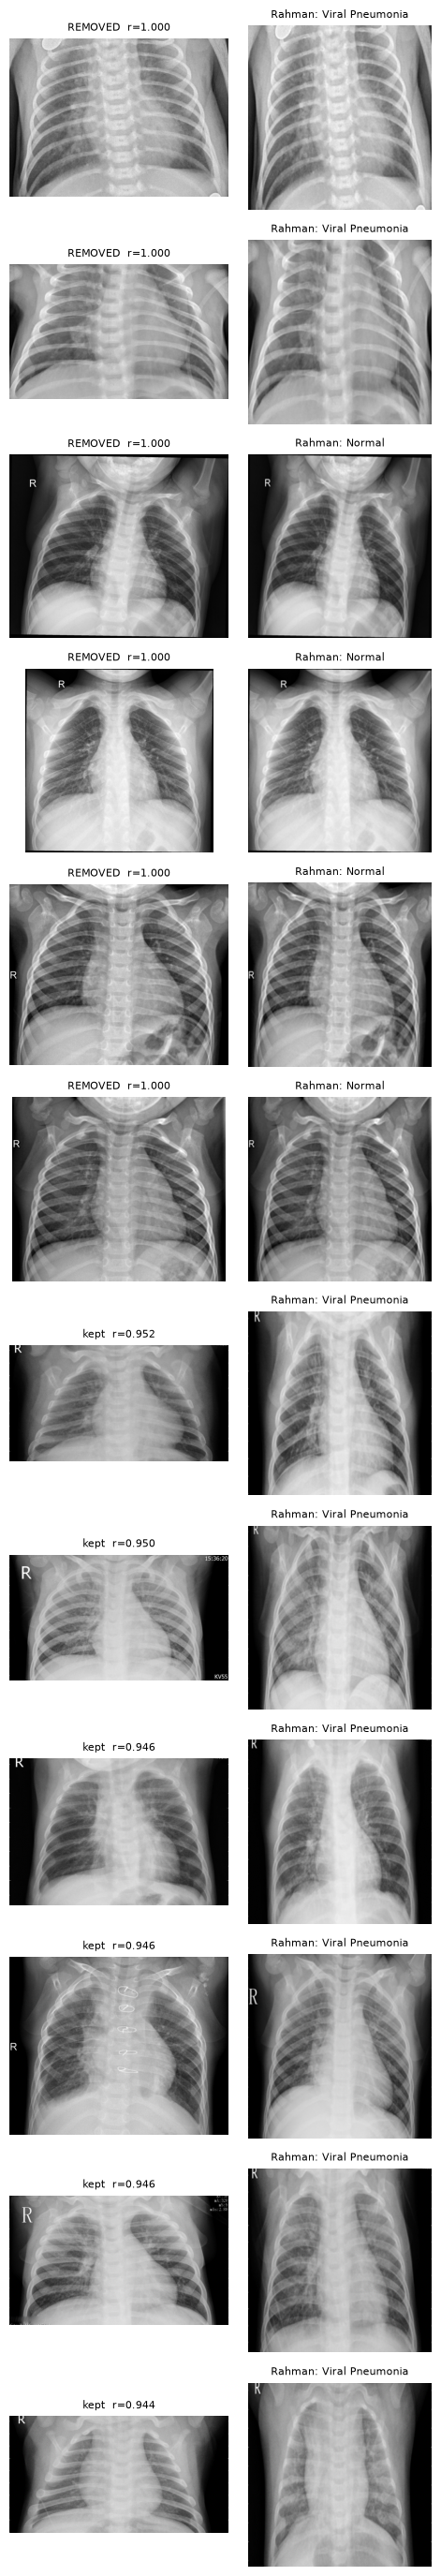

2026-11-10 00:13:18 | kermany_test: removed 271/586 images matching whole Rahman dataset (NCC >= 0.98) | label counts {0: 158, 1: 428} -> {0: 22, 1: 293}
2026-11-10 00:13:18 | kermany_test_norahman: 315 images | {'PNEUMONIA': 293, 'NORMAL': 22}
2026-11-10 00:13:19 | Cohen: classes in split {'PNEUMONIA': 428, 'NORMAL': 159, 'COVID19': 57} -> keeping NORMAL vs PNEUMONIA
2026-11-10 00:13:19 | cohen_test: 587 images | {'PNEUMONIA': 428, 'NORMAL': 159}
2026-11-10 00:13:21 | Cohen: classes in split {'PNEUMONIA': 428, 'NORMAL': 159, 'COVID19': 57} -> keeping NORMAL vs PNEUMONIA


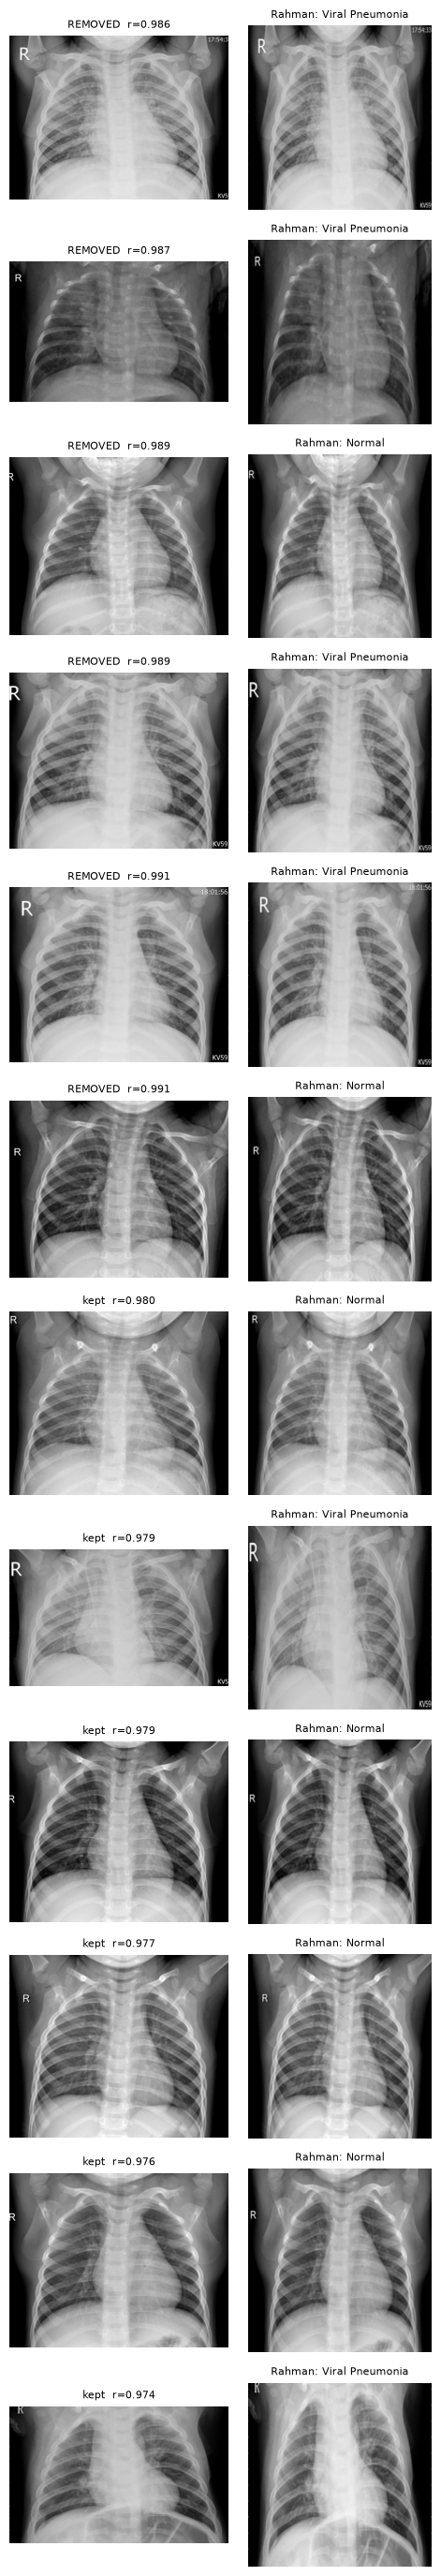

2026-11-10 00:13:27 | cohen_test: removed 191/587 images matching whole Rahman dataset (NCC >= 0.98) | label counts {0: 159, 1: 428} -> {0: 61, 1: 335}
2026-11-10 00:13:27 | cohen_test_norahman: 396 images | {'PNEUMONIA': 335, 'NORMAL': 61}
2026-11-10 00:13:28 | Cohen 3-class: classes in split {'PNEUMONIA': 428, 'NORMAL': 159, 'COVID19': 57} -> keeping ['COVID19', 'NORMAL', 'PNEUMONIA']
2026-11-10 00:13:28 | cohen3_test: 644 images | {'PNEUMONIA': 428, 'NORMAL': 159, 'COVID19': 57}
2026-11-10 00:13:29 | Cohen 3-class: classes in split {'PNEUMONIA': 428, 'NORMAL': 159, 'COVID19': 57} -> keeping ['COVID19', 'NORMAL', 'PNEUMONIA']


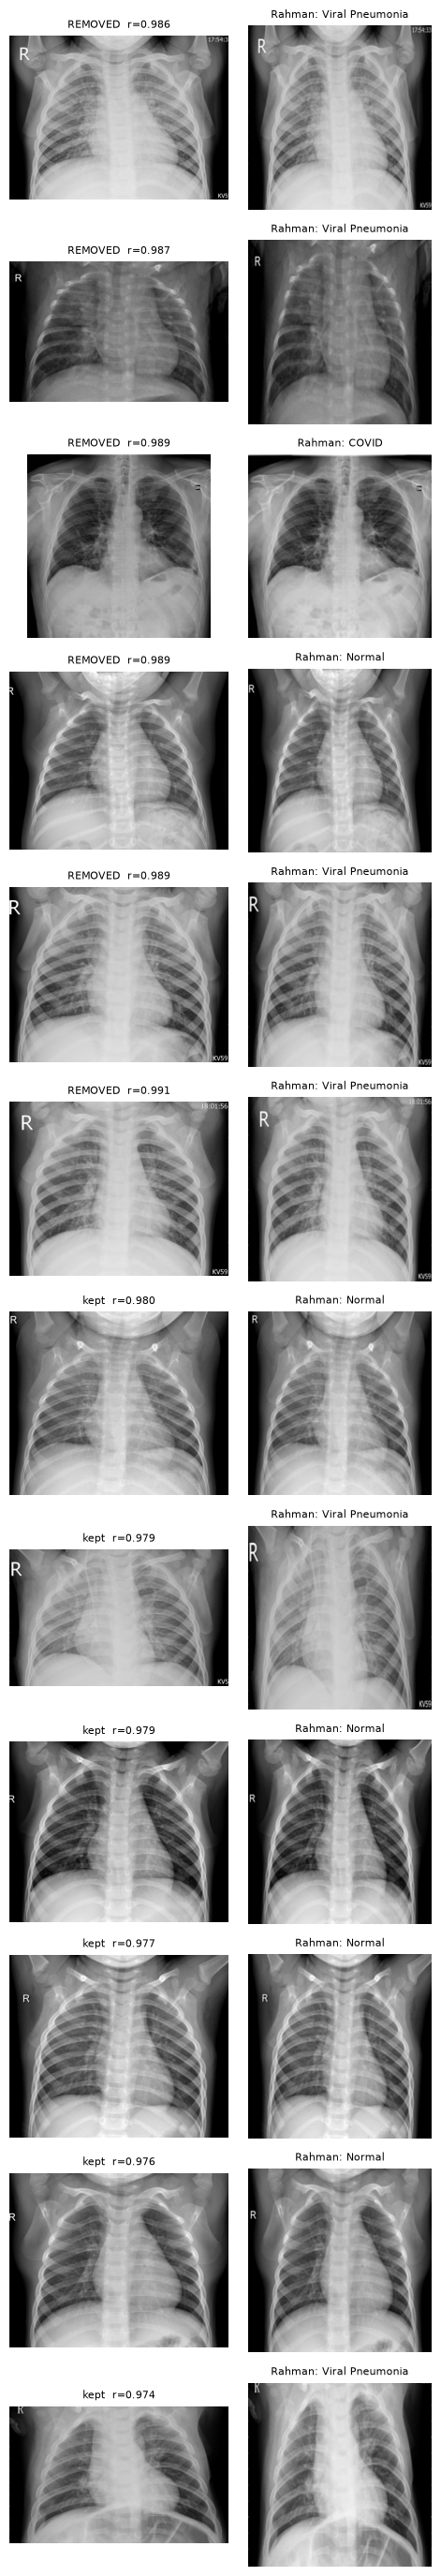

2026-11-10 00:13:36 | cohen3_test: removed 221/644 images matching whole Rahman dataset (NCC >= 0.98) | label counts {0: 57, 1: 159, 2: 428} -> {0: 27, 1: 61, 2: 335}
2026-11-10 00:13:36 | cohen3_test_norahman: 423 images | {'PNEUMONIA': 335, 'NORMAL': 61, 'COVID19': 27}
2026-11-10 00:13:36 | [rahman-full] weights not found at ./model/weights/mask_exp/dsa_eca_LN_rahman42.pth, skipped
2026-11-10 00:13:36 | [rahman-eca] weights not found at ./model/weights/mask_exp/eca_LN_rahman42.pth, skipped
2026-11-10 00:13:36 | [rahman-full-aug] weights not found at ./model/weights/mask_exp/dsa_eca_LN_rahman42_aug.pth, skipped
2026-11-10 00:13:36 | [rahman-eca-aug] weights not found at ./model/weights/mask_exp/eca_LN_rahman42_aug.pth, skipped


In [ ]:
# ============== Register the filtered test sets and run the evaluation (separate output folder) ==============
def _no_rahman(base_key):
    return lambda: drop_rahman_matches(BUILDERS[base_key][1](), base_key)

for _base in ("kermany_test", "cohen_test", "cohen3_test"):
    BUILDERS[f"{_base}_norahman"] = (BUILDERS[_base][0], _no_rahman(_base))
THREE_CLASS.add("cohen3_test_norahman")

NR_DATASETS = ["kermany_test", "kermany_test_norahman", "cohen_test", "cohen_test_norahman",
               "cohen3_test", "cohen3_test_norahman"]          # unfiltered + filtered side by side (drop the unfiltered ones to save time)

NR_DIR.mkdir(parents=True, exist_ok=True)
(NR_DIR / "overlap_check_config.json").write_text(json.dumps(dict(
    thumb=THUMB, ncc_threshold=NCC_THRESHOLD, rahman_split_csv_dir=RAHMAN_SPLIT_CSV_DIR,
    rahman_ref_splits=list(RAHMAN_REF_SPLITS), datasets=NR_DATASETS), indent=2))

_prev = (EXT_DIR, DATASETS_TO_RUN, CHECK_COHEN_OVERLAP)
EXT_DIR, DATASETS_TO_RUN, CHECK_COHEN_OVERLAP = NR_DIR, NR_DATASETS, False
try:
    results_nr = main()
    clean_report(results_nr, NR_DIR)
finally:
    EXT_DIR, DATASETS_TO_RUN, CHECK_COHEN_OVERLAP = _prev

In [ ]:
# ============== Compare: full test set vs test set without Rahman matches (one file per model) ==============
SUFFIX = "_norahman"
METRICS = dict(binary=["auroc", "sensitivity", "specificity", "balanced_accuracy"],
               three_class=["accuracy", "balanced_accuracy", "macro_f1", "auc_micro", "auroc_macro_ovr"])

for mname, res in results_nr.items():
    for kind, keys in METRICS.items():
        df = res[kind]
        if not len(df):
            continue
        is_nr = df["dataset"].str.endswith(SUFFIX)
        full = df[~is_nr]
        nr = df[is_nr].assign(dataset=lambda d: d["dataset"].str.removesuffix(SUFFIX))
        cmp_ = full.merge(nr, on=["model", "variant", "dataset"], suffixes=("", "_nr"))
        for k in keys:
            cmp_[f"d_{k}"] = cmp_[f"{k}_nr"] - cmp_[k]                # filtered minus full
        cols = ["model", "variant", "dataset", "n", "n_nr"] + [c for k in keys for c in (k, f"{k}_nr", f"d_{k}")]
        cmp_[cols].to_csv(NR_DIR / mname / f"comparison_full_vs_no_rahman_{kind}.csv", index=False)
        print(f"\n===== {mname} | {kind}: full vs without Rahman matches (d = filtered - full) =====")
        print(cmp_[cols].round(4).to_string(index=False))
    shutil.make_archive(str(NR_DIR / mname), "zip", root_dir=NR_DIR / mname)   # refresh the per-model zip with the comparison files